# Prompts, decoding parameters and synthetic data

*Follows on from [1](1-generating-one-token-at-a-time.ipynb), where GPT-2 picked the single most probable next token. Here I take the same next-token distribution and look at everything that happens between it and the text you get back. The next notebook, [6.1](6.1-chain-of-thought-and-response-triggers.ipynb), puts these ideas to work with chain-of-thought prompting on Qwen 2 1.5B.*

An LLM does not output text. At each step it outputs a **probability distribution over its vocabulary**, and a separate decoding procedure, controlled by parameters such as `temperature` and `top_p`, turns that distribution into one token. This notebook covers:

| Part | Question | How it is answered |
|---|---|---|
| 1 | What is a prompt, mathematically? | $P(Y \mid X, \theta)$ and the chain rule, checked numerically on GPT-2 |
| 2 | What does each decoding parameter do? | The formula for each one, a worked 6-token example, real GPT-2 distributions, a comparison matrix |
| 3 | How do I experiment reproducibly? | Greedy decoding, a task with a known answer, token probabilities |
| 4 | What goes wrong with few-shot prompts and greedy decoding? | The "being, binge" loop reproduced and measured; few-shot anagrams on gpt-oss-120b |
| 5 | How can an LLM generate training data? | The three formats (responses, back-translated instructions, preferences), with their training objectives and a small live run |
| 6 | Where do API playgrounds fit? | How playground settings map to the request body |

Parts 1 to 4 run locally on GPT-2. Parts 4b and 5 call gpt-oss-120b through Together AI and are skipped if no API key is set (see the setup cell).

In [1]:
import json
import os
import re
import warnings
from collections import Counter

warnings.filterwarnings("ignore")

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import requests
import torch
import transformers
from matplotlib.patches import FancyBboxPatch

transformers.logging.set_verbosity_error()
transformers.utils.logging.disable_progress_bar()
torch.manual_seed(0)

# One plotting style for the whole notebook (same as notebooks 4 to 5)
BLUE, ORANGE, AQUA, YELLOW = "#2a78d6", "#eb6834", "#1baf7a", "#eda100"
INK, SECONDARY, MUTED, GRID, SURFACE = "#0b0b0b", "#52514e", "#898781", "#e1e0d9", "#fcfcfb"
plt.rcParams.update(
    {
        "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
        "figure.dpi": 110, "savefig.dpi": 160, "savefig.bbox": "tight", "font.size": 10,
        "axes.titlesize": 11, "axes.titleweight": "bold", "axes.titlelocation": "left",
        "axes.edgecolor": "#c3c2b7", "axes.labelcolor": SECONDARY,
        "axes.spines.top": False, "axes.spines.right": False,
        "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.6, "axes.axisbelow": True,
        "xtick.color": MUTED, "ytick.color": MUTED, "text.color": INK,
        "lines.linewidth": 2, "legend.frameon": False,
    }
)
os.makedirs("assets", exist_ok=True)
os.makedirs("data", exist_ok=True)


# Together AI key: read from the environment, or from a local .env file (ignored by git).
def load_together_key():
    key = os.getenv("TOGETHER_API_KEY")
    if not key and os.path.exists(".env"):
        for line in open(".env"):
            if line.strip().startswith("TOGETHER_API_KEY="):
                key = line.split("=", 1)[1].strip().strip('"').strip("'")
    return key


def together_key_works(key):
    """One cheap call to list models: True if Together accepts the key."""
    if not key:
        return False
    try:
        r = requests.get("https://api.together.xyz/v1/models", headers={"Authorization": f"Bearer {key}"}, timeout=20)
    except requests.RequestException as e:
        print("Could not reach Together AI:", e)
        return False
    if r.status_code == 401:
        print("Together AI rejected the key (401). Use the full secret key (it starts with 'tgp_v1_'), "
              "not the key ID shown in the dashboard list ('key_...'), then restart the kernel.")
    return r.ok


TOGETHER_API_KEY = load_together_key()
# Together no longer serves Llama 3.x on demand. gpt-oss-120b (OpenAI, open weights, Apache 2.0) is a reasoning model:
# it writes hidden reasoning before its answer (see together_chat in Part 4b).
TOGETHER_MODEL = "openai/gpt-oss-120b"
TOGETHER_AVAILABLE = together_key_works(TOGETHER_API_KEY)

print(f"torch {torch.__version__} | transformers {transformers.__version__}")
print(f"Together AI: {'key found, ' + TOGETHER_MODEL if TOGETHER_AVAILABLE else 'no working key, parts 4b and 5 will be skipped'}")

torch 2.14.1 | transformers 5.19.0
Together AI: key found, openai/gpt-oss-120b


In [2]:
from transformers import AutoModelForCausalLM, AutoTokenizer

# GPT-2 small, the same model as notebook 1. CPU keeps every number in this notebook reproducible.
tokenizer = AutoTokenizer.from_pretrained("openai-community/gpt2")
gpt2 = AutoModelForCausalLM.from_pretrained("openai-community/gpt2").eval()
V = gpt2.config.vocab_size


@torch.no_grad()
def next_token_logits(text_or_ids):
    """Raw logits z for the next token after a prompt (a string or a list of token ids)."""
    ids = tokenizer.encode(text_or_ids) if isinstance(text_or_ids, str) else list(text_or_ids)
    return gpt2(torch.tensor([ids])).logits[0, -1].double().numpy()


def softmax(z):
    z = z - z.max()                  # subtracting a constant does not change softmax, and avoids overflow
    e = np.exp(z)
    return e / e.sum()


def show_top(p, k=8):
    idx = np.argsort(-p)[:k]
    return pd.DataFrame({"token": [repr(tokenizer.decode(int(i))) for i in idx], "probability": p[idx].round(4)})


print(f"vocabulary size |V| = {V:,}")

vocabulary size |V| = 50,257


# Part 1: What is a prompt

## $P(Y \mid X, \theta)$

A prompt is the conditioning information in

$$P(Y \mid X, \theta)$$

| Symbol | In classical ML | In an LLM |
|---|---|---|
| $X$ | the features | the prompt: system prompt, user prompt, conversation history, everything in the context window |
| $Y$ | the label / prediction | the response (in pre-training: the masked or next token) |
| $\theta$ | the model weights | the model weights |

Prompting is the part of the problem where $\theta$ is fixed and only $X$ can be changed. Fine-tuning (notebooks 4 to 5) is the opposite: $X$ is given, $\theta$ is changed.

## The response is generated one token at a time

An LLM does not produce $Y$ in one go. Write the prompt as tokens $x_1, \dots, x_n$ and the response as $y_1, \dots, y_m$. By the chain rule of probability, *with no approximation*:

$$P(Y \mid X) \;=\; \prod_{t=1}^{m} P\big(y_t \;\big|\; \underbrace{x_1, \dots, x_n}_{\text{prompt}},\; \underbrace{y_1, \dots, y_{t-1}}_{\text{generated so far}}\big).$$

The model only ever computes one factor at a time. After each step, the chosen token is appended to the input. Writing $X_{1..j}$ for the first $j$ tokens of the growing input, a prompt of $n$ tokens that ends as a prompt + response of $k$ tokens is built as:

$$P(Y_{n+1} \mid X_{1..n}) \;\to\; P(Y_{n+2} \mid X_{1..n+1}) \;\to\; P(Y_{n+3} \mid X_{1..n+2}) \;\to\; \cdots \;\to\; P(Y_k \mid X_{1..k-1}).$$

So tokens $n+1$ to $k-1$ of the input were **written by the model itself**. That has two consequences, both seen later in this notebook:

- **Vicious feedback loop** (Part 4). If the model writes a repeated pattern, the pattern is now in its own input, which makes repeating it even more probable.
- **Virtuous feedback loop** (notebook 6.1). If the model first writes useful intermediate steps, such as the arithmetic of a word problem, those steps become input features for the tokens that come after them. Chain-of-thought prompting makes use of this: the model writes part of its own $X$.

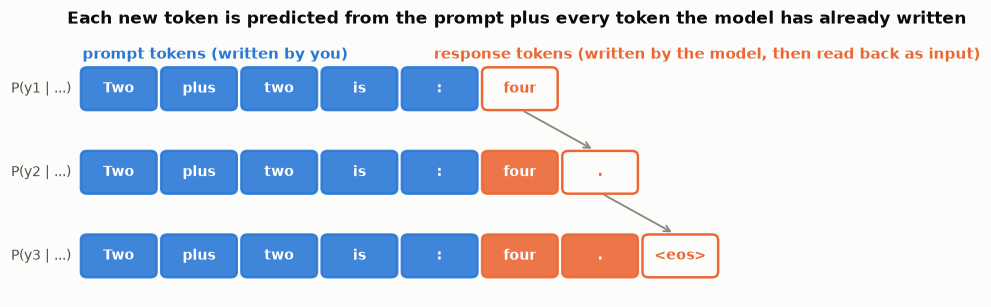

In [3]:
# Figure: the input grows by one model-written token per step
steps = [("prompt", 5, 0), ("step 1", 5, 1), ("step 2", 5, 2), ("step 3", 5, 3)]
fig, ax = plt.subplots(figsize=(9.5, 3.0))
ax.set_xlim(-0.2, 10.4); ax.set_ylim(0.2, 4.0); ax.axis("off")
words_prompt = ["Two", "plus", "two", "is", ":"]
words_gen = ["four", ".", "<eos>"]
for row, (label, n_prompt, n_gen) in enumerate(steps[1:]):
    y = 3 - row * 1.25
    ax.text(-0.15, y + 0.3, f"P(y{n_gen} | ...)", ha="right", va="center", fontsize=9, color=SECONDARY)
    for j in range(n_prompt + n_gen):
        is_prompt = j < n_prompt
        color = BLUE if is_prompt else ORANGE
        is_new = j == n_prompt + n_gen - 1 and not is_prompt
        ax.add_patch(FancyBboxPatch((j * 1.05, y), 0.95, 0.6, boxstyle="round,pad=0.02,rounding_size=0.08",
                                    facecolor=color if not is_new else SURFACE, edgecolor=color, linewidth=1.6,
                                    alpha=0.9 if not is_new else 1))
        word = words_prompt[j] if is_prompt else words_gen[j - n_prompt]
        ax.text(j * 1.05 + 0.475, y + 0.3, word, ha="center", va="center", fontsize=9,
                color="white" if not is_new else ORANGE, fontweight="bold")
    if n_gen < 3:
        ax.annotate("", xy=((n_prompt + n_gen) * 1.05 + 0.4, y - 0.62), xytext=((n_prompt + n_gen - 1) * 1.05 + 0.5, y - 0.02),
                    arrowprops=dict(arrowstyle="->", color=MUTED, lw=1.2))
ax.text(0, 3.75, "prompt tokens (written by you)", color=BLUE, fontweight="bold", fontsize=9.5)
ax.text(4.6, 3.75, "response tokens (written by the model, then read back as input)", color=ORANGE, fontweight="bold", fontsize=9.5)
ax.set_title("Each new token is predicted from the prompt plus every token the model has already written", pad=12)
plt.savefig("assets/6-autoregressive-loop.png")
plt.show()

The outlined box at the end of each row is the token being predicted at that step. In the next row it is filled in and is part of the input.

**Checking the chain rule on GPT-2.** Below I take a prompt and a fixed continuation and compute $\log P(Y \mid X)$ two ways: (a) one forward pass over prompt + response, reading off each response token's log-probability, and (b) $m$ separate calls, each seeing only the prompt and the tokens before it, exactly as generation does. The two sums should agree up to rounding (GPT-2 computes in 32-bit floats, so about 4 to 5 decimal places).

In [4]:
prompt = "The capital of France is"
response = " Paris, and the capital of Italy is Rome."
x_ids, y_ids = tokenizer.encode(prompt), tokenizer.encode(response)

# (a) one forward pass over prompt + response
with torch.no_grad():
    logp_all = torch.log_softmax(gpt2(torch.tensor([x_ids + y_ids])).logits[0].double(), dim=-1)
one_pass = [logp_all[len(x_ids) + t - 1, y].item() for t, y in enumerate(y_ids)]

# (b) one call per token, as during generation
step_by_step = [np.log(softmax(next_token_logits(x_ids + y_ids[:t]))[y]) for t, y in enumerate(y_ids)]

table = pd.DataFrame({
    "t": range(1, len(y_ids) + 1),
    "token y_t": [repr(tokenizer.decode(y)) for y in y_ids],
    "P(y_t | x, y_<t)": np.exp(step_by_step).round(4),
    "log P (step by step)": np.round(step_by_step, 4),
    "log P (one pass)": np.round(one_pass, 4),
})
print(f"log P(Y|X), sum of step-by-step terms : {sum(step_by_step):.6f}")
print(f"log P(Y|X), sum from one forward pass : {sum(one_pass):.6f}")
print(f"P(Y|X) = exp(sum)                     : {np.exp(sum(step_by_step)):.3e}")
table

log P(Y|X), sum of step-by-step terms : -14.806627
log P(Y|X), sum from one forward pass : -14.806661
P(Y|X) = exp(sum)                     : 3.712e-07


,t,token y_t,"P(y_t | x, y_<t)",log P (step by step),log P (one pass)
0,1,' Paris',0.0322,-3.4345,-3.4345
1,2,"','",0.4505,-0.7975,-0.7975
2,3,' and',0.1938,-1.6407,-1.6407
3,4,' the',0.1621,-1.8196,-1.8196
4,5,' capital',0.2090,-1.5653,-1.5653
5,6,' of',0.6402,-0.4460,-0.4460
6,7,' Italy',0.0188,-3.9752,-3.9752
7,8,' is',0.7643,-0.2688,-0.2688
8,9,' Rome',0.5769,-0.5501,-0.5501
9,10,'.',0.7341,-0.3091,-0.3091


The per-token columns match to 4 decimal places and the totals ($-14.80663$ against $-14.80666$) differ only by 32-bit rounding, so the factorization is exact, not an approximation. Two things in the table are worth noticing:

- The probability of a token depends on what came before it. GPT-2 gives " Paris" only 3.2% after "The capital of France is", but " Rome" 57.7% after "... and the capital of Italy is": by then the model has its own earlier pattern (" Paris, and the capital of") to condition on.
- The probability of the whole sentence is $e^{-14.81} \approx 3.7 	imes 10^{-7}$ even though every token is reasonable, because it is a product of ten numbers below 1. This is why APIs report **log**-probabilities: sums of logs stay in a usable range.

# Part 2: Decoding parameters

## From logits to one token

For every token $i$ in the vocabulary $V$ (50,257 tokens for GPT-2), the model outputs a real number $z_i$, the **logit**. Softmax turns logits into probabilities:

$$p_i = \frac{e^{z_i}}{\sum_{j \in V} e^{z_j}}.$$

### The vocabulary: what the 50,257 tokens are

GPT-2 never sees letters or words, only token ids. Its tokenizer uses **byte-pair encoding (BPE)**: start from the 256 possible bytes, so any text at all can be written, then repeatedly merge the most frequent adjacent pair in the training text into a new token. GPT-2 did 50,000 merges and added one special token, `<|endoftext|>`, which marks the end of a document and plays the role of `<eos>` in the figure above.

In [5]:
# Where GPT-2's 50,257 tokens come from, and how text is split into them
n_merges = len(json.loads(tokenizer.backend_tokenizer.to_str())["model"]["merges"])
print(f"single bytes        {256:>6,}")
print(f"learned BPE merges  {n_merges:>6,}")
print(f"special tokens      {1:>6,}   {tokenizer.eos_token!r} (id {tokenizer.eos_token_id})")
print(f"total               {256 + n_merges + 1:>6,}   (model vocabulary: {V:,})")
print()
for text in ["two", " two", " Two", "Thermopylae", " tokenization", "🧬"]:
    ids = tokenizer.encode(text)
    print(f"{text!r:16} -> {len(ids)} token(s): {[tokenizer.decode([i]) for i in ids]}  ids {ids}")

single bytes           256
learned BPE merges  50,000
special tokens           1   '<|endoftext|>' (id 50256)
total               50,257   (model vocabulary: 50,257)

'two'            -> 1 token(s): ['two']  ids [11545]
' two'           -> 1 token(s): [' two']  ids [734]
' Two'           -> 1 token(s): [' Two']  ids [4930]
'Thermopylae'    -> 4 token(s): ['Ther', 'mop', 'yl', 'ae']  ids [35048, 35244, 2645, 3609]
' tokenization'  -> 2 token(s): [' token', 'ization']  ids [11241, 1634]
'🧬'              -> 3 token(s): ['�', '�', '�']  ids [8582, 100, 105]


Common words are one token, and the leading space is part of the token: `"two"`, `" two"` and `" Two"` are three unrelated ids (11545, 734 and 4930), so the model has to learn separately that they mean the same thing. Rare words are split into pieces it has seen (`Ther` + `mop` + `yl` + `ae`). The DNA emoji is not in the vocabulary at all, so it falls back to its 3 raw UTF-8 bytes, none of which is printable on its own. Llama 3 uses the same idea with about 128,000 tokens, and gpt-oss about 200,000.

### Logits on a real prompt

At every step the last layer maps the model's 768-number hidden vector to one score per vocabulary token, a matrix of $768 \times 50{,}257 \approx 38.6$M weights (GPT-2 reuses its input embedding matrix here). Those 50,257 scores are the logits $z$. Below are the logits for the token after *"Two plus two is"*, the prompt of the figure above, with the five most likely tokens, the two "correct" answers, and everything else added up. The column $e^{z - \max z}$ is the numerator of softmax after subtracting the largest logit, which is how softmax is computed in practice (the `softmax` function above does the same).

In [6]:
z = next_token_logits("Two plus two is")
p = softmax(z)
order = np.argsort(-z)
rank = {int(i): r + 1 for r, i in enumerate(order)}
shown = [int(i) for i in order[:5]] + [tokenizer.encode(t)[0] for t in [" four", " 4"]]
rest = np.setdiff1d(np.arange(V), shown)

rows = [(rank[i], repr(tokenizer.decode([i])), z[i], z[i] - z.max(), np.exp(z[i] - z.max()), p[i]) for i in shown]
rows.append(("", f"the other {len(rest):,} (median logit)", np.median(z[rest]), np.median(z[rest]) - z.max(),
             np.exp(z[rest] - z.max()).sum(), p[rest].sum()))
table = pd.DataFrame(rows, columns=["rank", "token", "logit z", "z - max z", "e^(z - max z)", "probability"])
print(table.round(4).to_string(index=False))
print(f"\nall logits lie between {z.min():.1f} and {z.max():.1f}")
print("adding 100 to every logit changes the probabilities:", not np.allclose(softmax(z + 100), p))
print(f"p(' a') / p(' the') = {p[order[0]] / p[order[1]]:.3f},  e^(gap in logits) = {np.exp(z[order[0]] - z[order[1]]):.3f}")

rank                           token   logit z  z - max z  e^(z - max z)  probability
   1                            ' a'  -90.1893     0.0000         1.0000       0.1436
   2                          ' the'  -90.4785    -0.2892         0.7489       0.1075
   3                          ' not'  -91.9330    -1.7437         0.1749       0.0251
   4                           ' an'  -91.9954    -1.8061         0.1643       0.0236
   5                         ' that'  -92.1104    -1.9211         0.1464       0.0210
  65                         ' four'  -94.5690    -4.3797         0.0125       0.0018
 104                            ' 4'  -95.0647    -4.8754         0.0076       0.0011
     the other 50,250 (median logit) -102.6232   -12.4339         4.7093       0.6762

all logits lie between -117.0 and -90.2
adding 100 to every logit changes the probabilities: False
p(' a') / p(' the') = 1.335,  e^(gap in logits) = 1.335


**Reading the table.**

1. **Only differences between logits matter.** Every logit is around $-90$, and adding 100 to all of them gives exactly the same probabilities. A logit on its own means nothing; the gap to the other logits is what counts. " a" is ahead of " the" by 0.29, so it is $e^{0.29} = 1.34$ times as likely.
2. **The tail is large.** No single token outside the top five has more than 2.1%, but there are 50,250 of them and together they hold 68% of the probability. Sampling at $T = 1$ with no truncation picks one of them two times out of three. This is the problem top-k and top-p (below) exist to solve.
3. **GPT-2 does not answer the question.** " four" is ranked 65th with 0.2%. GPT-2 small is a 124M-parameter model trained to continue web text, not to answer, and on the web "Two plus two is" is more often followed by " a", " the" or " not" (as in "two plus two is not five").

The prompt is the conditioning $X$ in $P(Y \mid X, \theta)$, so changing it moves these numbers. The cell below scores the two answers under a few prompts.

In [7]:
rows = []
for prompt in ["Two plus two is", "Two plus two is equal to", "2 + 2 =", "1 + 1 = 2. 2 + 2 ="]:
    z = next_token_logits(prompt)
    p = softmax(z)
    order = np.argsort(-z)
    row = {"prompt": repr(prompt), "top token": f"{tokenizer.decode([int(order[0])])!r} ({p[order[0]]:.3f})"}
    for t in [" four", " 4"]:
        i = tokenizer.encode(t)[0]
        row[f"{t!r} rank"] = int(np.where(order == i)[0][0]) + 1
        row[f"{t!r} p"] = round(float(p[i]), 3)
    rows.append(row)
pd.DataFrame(rows)

,prompt,top token,' four' rank,' four' p,' 4' rank,' 4' p
0,'Two plus two is',' a' (0.144),65,0.002,104,0.001
1,'Two plus two is equal to',' one' (0.108),7,0.029,15,0.012
2,'2 + 2 =',' 3' (0.102),364,0.000,5,0.055
3,'1 + 1 = 2. 2 + 2 =',' 3' (0.471),288,0.000,3,0.123


Writing the question as arithmetic moves " 4" from rank 104 to rank 5, and one worked example before it ("1 + 1 = 2.") moves it to rank 3 with 12%. The top token is still wrong (" 3" at 47%): a 124M model has picked up the *format* "number = number" from the example, but not the arithmetic. Prompts can only reweight what the model has already learned, a point Part 4 comes back to. Larger instruction-tuned models answer questions like this one easily, but [notebook 6.1](6.1-chain-of-thought-and-response-triggers.ipynb) shows that a 1.5B instruction-tuned model still gets multi-step subtraction wrong, whatever the prompt.

A decoding method then picks one token from $p$. Inference APIs expose the same small set of controls. In the order Hugging Face `generate` applies them (other servers may order them differently):

| Step | Parameter | What it does to the distribution |
|---|---|---|
| 1 | `repetition_penalty` $\theta$ | Lowers the logits of tokens that already appear in the text |
| 1' | `frequency_penalty` $\alpha_f$, `presence_penalty` $\alpha_p$ | Same goal, additive instead of multiplicative (OpenAI-style APIs) |
| 2 | `temperature` $T$ | Divides every logit by $T$: sharpens ($T<1$) or flattens ($T>1$) the distribution |
| 3 | `top_k` $K$ | Keeps only the $K$ most probable tokens |
| 4 | `top_p` $p$ | Keeps the smallest set of top tokens whose probabilities add up to at least $p$ |
| 4' | `min_p` | Keeps tokens with at least `min_p` times the probability of the top token |
| 5 | sample | Draws one token from what is left, after renormalizing |

Plus three controls that do not change the distribution: `max_tokens` (stop after this many tokens), `stop` (stop when one of these strings is generated) and `logprobs` (return the probabilities of the chosen tokens).

**Greedy decoding** skips all of this and takes $\hat{y} = \arg\max_i z_i$. Setting $T = 0$ in an API means greedy decoding.

## Each parameter, with its formula

**Temperature.**

$$p_i(T) = \frac{e^{z_i / T}}{\sum_j e^{z_j / T}}, \qquad \frac{p_i(T)}{p_j(T)} = e^{(z_i - z_j)/T}.$$

The ratio on the right is the clearest way to see it. The gap between two logits is divided by $T$. With $T < 1$ the gaps grow and the top token takes more of the probability; with $T > 1$ they shrink and the distribution flattens. At the limits, $T \to 0$ gives all the probability to the top token (greedy), and $T \to \infty$ gives the uniform distribution $1/|V|$. **The order of the tokens never changes**, only how far apart they are.

How spread out a distribution is can be measured by its entropy, $H = -\sum_i p_i \log p_i$ (0 when one token has all the probability, $\log |V|$ when all are equal). Writing $\beta = 1/T$, a short calculation gives

$$\frac{dH}{dT} = \frac{\operatorname{Var}_{p(T)}(z)}{T^3} \;\ge\; 0,$$

so raising the temperature can never make the distribution more concentrated. This is checked numerically below.

**Top-k.** Keep the set $V_K$ of the $K$ highest-probability tokens and renormalize:

$$p_i^{\text{top-}k} = \frac{p_i\,\mathbb{1}[i \in V_K]}{\sum_{j \in V_K} p_j}.$$

**Top-p (nucleus sampling, Holtzman et al., 2020).** Sort the probabilities, $p_{(1)} \ge p_{(2)} \ge \dots$, and keep the smallest number of top tokens whose total reaches $p$:

$$k^\ast = \min\Big\{k : \sum_{r=1}^{k} p_{(r)} \ge p\Big\}, \qquad V_p = \{(1), \dots, (k^\ast)\},$$

then renormalize over $V_p$ as for top-k. The difference from top-k: **the number of tokens kept adapts to the model's confidence.** A confident distribution keeps a handful; an uncertain one keeps hundreds. `top_p = 1` turns it off.

**Min-p (Nguyen et al., 2024).** Keep $\{i : p_i \ge \text{min\_p} \cdot \max_j p_j\}$. The threshold is relative to the top token, so it also adapts to confidence.

**Repetition penalty (Keskar et al., 2019, the form used by Hugging Face and Together).** For every token $i$ that already appears in the prompt or the response:

$$z_i \leftarrow \begin{cases} z_i / \theta & z_i > 0 \\ z_i \cdot \theta & z_i \le 0 \end{cases}$$

With $\theta > 1$ both cases move $z_i$ down. It is applied once per token, whether the token appeared once or ten times. $\theta = 1$ turns it off.

**Frequency and presence penalties (OpenAI-style APIs).** With $c_i$ the number of times token $i$ has appeared so far:

$$z_i \leftarrow z_i - \alpha_f \, c_i - \alpha_p \, \mathbb{1}[c_i > 0].$$

The frequency penalty grows with every repetition; the presence penalty is a one-off charge for having appeared at all. Both are 0 by default; OpenAI allows $-2$ to $2$.

In [8]:
# The decoding pipeline, written out step by step in NumPy

def repetition_penalty(z, context_ids, theta):
    z = z.copy()
    for i in set(context_ids):
        z[i] = z[i] / theta if z[i] > 0 else z[i] * theta
    return z


def frequency_presence_penalty(z, context_ids, alpha_f, alpha_p):
    z = z.copy()
    for i, c in Counter(context_ids).items():
        z[i] -= alpha_f * c + alpha_p * (c > 0)
    return z


def with_temperature(z, T):
    return softmax(z / T)


def top_k_filter(p, k):
    keep = np.zeros_like(p, dtype=bool)
    keep[np.argsort(-p)[:k]] = True
    q = np.where(keep, p, 0.0)
    return q / q.sum()


def top_p_filter(p, top_p):
    order = np.argsort(-p)
    cumulative = np.cumsum(p[order])
    k_star = int(np.searchsorted(cumulative, top_p) + 1)     # smallest k with cumulative >= top_p
    keep = np.zeros_like(p, dtype=bool)
    keep[order[:k_star]] = True
    q = np.where(keep, p, 0.0)
    return q / q.sum()


def min_p_filter(p, min_p):
    q = np.where(p >= min_p * p.max(), p, 0.0)
    return q / q.sum()


def entropy(p):
    nz = p[p > 0]
    return float(-(nz * np.log(nz)).sum())

## A worked example with a six-token vocabulary

Before the real model, one pass through the pipeline by hand. A made-up model is completing *"The Eiffel Tower is in ..."*. The vocabulary has six tokens, and the earlier text already contains " London" (say the prompt mentioned it), so the repetition penalty applies to that one token.

In [9]:
toy_tokens = [" Paris", " London", " France", " the", " Berlin", " a"]
z = np.array([3.0, 2.2, 1.6, 0.9, 0.4, -0.5])
context = [1]                                   # " London" (index 1) already appears in the text

steps = {}
steps["0. softmax(z)"] = softmax(z)
z_rep = repetition_penalty(z, context, theta=1.3)
steps["1. repetition penalty 1.3"] = softmax(z_rep)
steps["2. temperature 0.7"] = with_temperature(z_rep, 0.7)
steps["3. top-k 4"] = top_k_filter(steps["2. temperature 0.7"], 4)
steps["4. top-p 0.9"] = top_p_filter(steps["3. top-k 4"], 0.9)

toy = pd.DataFrame(steps, index=toy_tokens).round(3)
toy.insert(0, "logit z", z)
toy.insert(1, "z after penalty", z_rep.round(3))
print("Step 1, by hand for ' London':  z = 2.2 > 0, so z / 1.3 =", round(2.2 / 1.3, 3))
print("Step 2, ratio Paris : London    before =", round(np.exp(3.0 - z_rep[1]), 2),
      "| after T=0.7 =", round(np.exp((3.0 - z_rep[1]) / 0.7), 2), "(= the gap divided by T, then exponentiated)")
cum = np.cumsum(np.sort(steps["3. top-k 4"])[::-1])
print("Step 4, cumulative top-k probabilities:", cum.round(3), "-> the first total >= 0.9 is reached at k* =",
      int(np.searchsorted(cum, 0.9) + 1))
toy

Step 1, by hand for ' London':  z = 2.2 > 0, so z / 1.3 = 1.692
Step 2, ratio Paris : London    before = 3.7 | after T=0.7 = 6.48 (= the gap divided by T, then exponentiated)
Step 4, cumulative top-k probabilities: [0.747 0.862 0.963 1.    1.    1.   ] -> the first total >= 0.9 is reached at k* = 3


,logit z,z after penalty,0. softmax(z),1. repetition penalty 1.3,2. temperature 0.7,3. top-k 4,4. top-p 0.9
Paris,3.0,3.000,0.520,0.573,0.730,0.747,0.775
London,2.2,1.692,0.234,0.155,0.113,0.115,0.120
France,1.6,1.600,0.128,0.141,0.099,0.101,0.105
the,0.9,0.900,0.064,0.070,0.036,0.037,0.000
Berlin,0.4,0.400,0.039,0.043,0.018,0.000,0.000
a,-0.5,-0.500,0.016,0.017,0.005,0.000,0.000


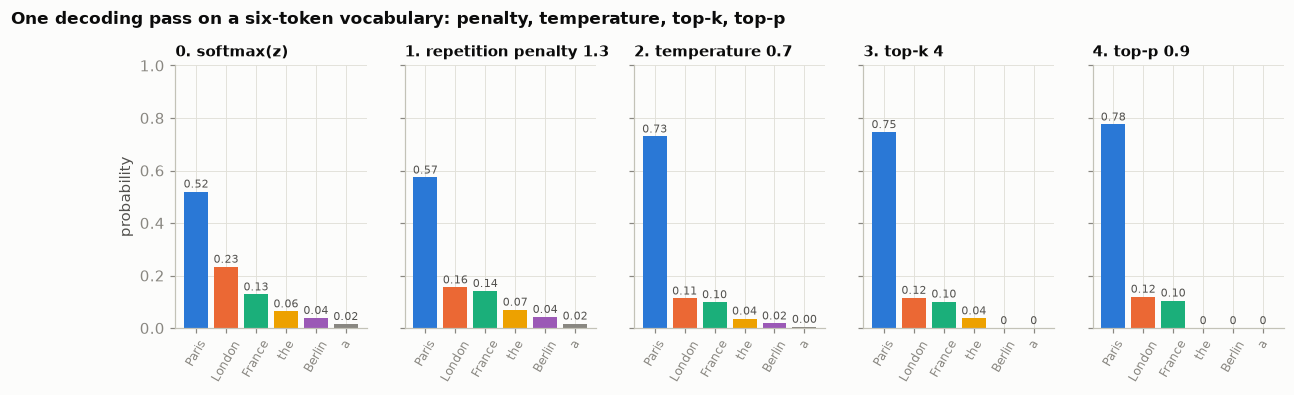

In [10]:
# Figure: the same six tokens after each step of the pipeline
fig, axes = plt.subplots(1, 5, figsize=(13, 3.1), sharey=True)
colors = [BLUE, ORANGE, AQUA, YELLOW, "#9b59b6", MUTED]
for ax, (name, p) in zip(axes, steps.items()):
    bars = ax.bar(range(6), p, color=[c if v > 0 else GRID for c, v in zip(colors, p)])
    ax.set_xticks(range(6)); ax.set_xticklabels([t.strip() for t in toy_tokens], rotation=60, fontsize=8)
    ax.set_title(name, fontsize=9.5)
    for i, v in enumerate(p):
        ax.text(i, v + 0.015, f"{v:.2f}" if v > 0 else "0", ha="center", fontsize=7, color=SECONDARY)
    ax.set_ylim(0, 1)
axes[0].set_ylabel("probability")
fig.suptitle("One decoding pass on a six-token vocabulary: penalty, temperature, top-k, top-p", x=0.01, ha="left",
             fontweight="bold", fontsize=11, y=1.04)
plt.savefig("assets/6-decoding-pipeline.png")
plt.show()

**Reading the worked example.**

1. **Penalty.** Only " London" is in the earlier text. Its logit is positive, so it is divided: $2.2 / 1.3 = 1.692$. Its probability drops from 0.234 to 0.155, and the other five tokens all gain a little, because softmax renormalizes.
2. **Temperature 0.7.** The logit gap between " Paris" and " London" is $3.0 - 1.692 = 1.308$. The probability ratio goes from $e^{1.308} = 3.70$ to $e^{1.308/0.7} = 6.48$. " Paris" rises from 0.573 to 0.730; the order of the six tokens is unchanged.
3. **Top-k 4.** " Berlin" and " a" (0.018 and 0.005) are removed, and the remaining four are divided by their total, 0.977.
4. **Top-p 0.9.** The running totals are 0.747, 0.862, 0.963: the first one at or above 0.9 is the third, so $k^\ast = 3$ and " the" is removed too.
5. **Sample.** The final draw is " Paris" with probability 0.775, " London" 0.120, " France" 0.105. Without any of these steps, " Paris" would have been drawn only 52% of the time.

**Checking my implementation against Hugging Face.** The NumPy functions above are my reading of the formulas. Hugging Face implements each step as a "logits processor". On a real GPT-2 distribution, the two should give the same probabilities.

In [11]:
from transformers import (MinPLogitsWarper, RepetitionPenaltyLogitsProcessor, TemperatureLogitsWarper,
                          TopKLogitsWarper, TopPLogitsWarper)

ids = tokenizer.encode("The Eiffel Tower is located in the city of")
z_real = next_token_logits(ids)
scores = torch.tensor(z_real).unsqueeze(0)
input_ids = torch.tensor([ids])


def hf_probs(processor):
    return torch.softmax(processor(input_ids, scores.clone()), dim=-1)[0].numpy()


checks = {
    "repetition penalty 1.3": (softmax(repetition_penalty(z_real, ids, 1.3)), hf_probs(RepetitionPenaltyLogitsProcessor(1.3))),
    "temperature 0.7": (with_temperature(z_real, 0.7), hf_probs(TemperatureLogitsWarper(0.7))),
    "top-k 50": (top_k_filter(softmax(z_real), 50), hf_probs(TopKLogitsWarper(50))),
    "top-p 0.9": (top_p_filter(softmax(z_real), 0.9), hf_probs(TopPLogitsWarper(0.9))),
    "min-p 0.05": (min_p_filter(softmax(z_real), 0.05), hf_probs(MinPLogitsWarper(0.05))),
}
pd.DataFrame(
    [(name, int((mine > 0).sum()), int((hf > 0).sum()), float(np.abs(mine - hf).max())) for name, (mine, hf) in checks.items()],
    columns=["step", "tokens kept (mine)", "tokens kept (HF)", "max |difference|"],
)

,step,tokens kept (mine),tokens kept (HF),max |difference|
0,repetition penalty 1.3,50257,50257,6.106227e-16
1,temperature 0.7,50257,50257,5.828671e-16
2,top-k 50,50,50,1.387779e-17
3,top-p 0.9,953,953,4.163336e-17
4,min-p 0.05,48,48,2.775558e-17


All five steps agree with Hugging Face to within $10^{-15}$ (floating-point rounding), with the same tokens kept. On this prompt top-p 0.9 keeps 953 of GPT-2's 50,257 tokens and min-p 0.05 keeps 48, a reminder that the two "adaptive" filters can be very different in strength.

## Temperature on a real distribution

GPT-2's distribution for the next token after *"The Eiffel Tower is located in the city of"* at four temperatures, followed by the entropy and the top token's probability as $T$ varies.

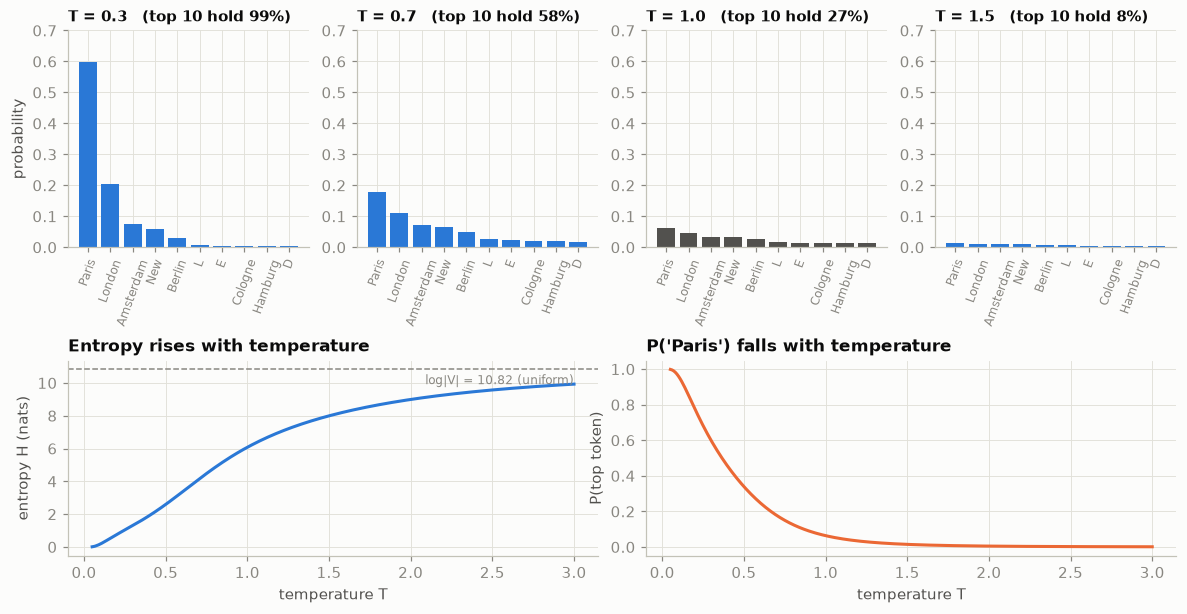

,T,dH/dT (finite difference),Var(z) / T^3 (formula)
0,0.5,7.19927,7.19927
1,1.0,5.40130,5.40130
2,2.0,1.48508,1.48508


In [12]:
temps = [0.3, 0.7, 1.0, 1.5]
p_base = softmax(z_real)
top_ids = np.argsort(-p_base)[:10]
labels = [tokenizer.decode(int(i)).strip() or repr(tokenizer.decode(int(i))) for i in top_ids]

fig = plt.figure(figsize=(13, 6.2))
gs = fig.add_gridspec(2, 4, height_ratios=[1, 0.9], hspace=0.55)
for col, T in enumerate(temps):
    ax = fig.add_subplot(gs[0, col])
    pT = with_temperature(z_real, T)
    ax.bar(range(10), pT[top_ids], color=BLUE if T != 1.0 else SECONDARY)
    ax.set_xticks(range(10)); ax.set_xticklabels(labels, rotation=70, fontsize=8)
    ax.set_ylim(0, 0.7)
    ax.set_title(f"T = {T}   (top 10 hold {pT[top_ids].sum():.0%})", fontsize=9.5)
    if col == 0:
        ax.set_ylabel("probability")

T_grid = np.linspace(0.05, 3, 300)
H = np.array([entropy(with_temperature(z_real, T)) for T in T_grid])
p_top = np.array([with_temperature(z_real, T).max() for T in T_grid])

ax = fig.add_subplot(gs[1, :2])
ax.plot(T_grid, H, color=BLUE)
ax.axhline(np.log(V), color=MUTED, ls="--", lw=1)
ax.text(3, np.log(V) - 0.9, f"log|V| = {np.log(V):.2f} (uniform)", ha="right", fontsize=8, color=MUTED)
ax.set_xlabel("temperature T"); ax.set_ylabel("entropy H (nats)"); ax.set_title("Entropy rises with temperature")
ax = fig.add_subplot(gs[1, 2:])
ax.plot(T_grid, p_top, color=ORANGE)
ax.set_xlabel("temperature T"); ax.set_ylabel("P(top token)"); ax.set_title(f"P('{labels[0]}') falls with temperature")
plt.savefig("assets/6-temperature.png")
plt.show()

# Numerical check of dH/dT = Var(z) / T^3 at a few temperatures
rows = []
for T in [0.5, 1.0, 2.0]:
    h = 1e-5
    finite_diff = (entropy(with_temperature(z_real, T + h)) - entropy(with_temperature(z_real, T - h))) / (2 * h)
    pT = with_temperature(z_real, T)
    variance = float((pT * z_real**2).sum() - (pT * z_real).sum() ** 2)
    rows.append((T, finite_diff, variance / T**3))
pd.DataFrame(rows, columns=["T", "dH/dT (finite difference)", "Var(z) / T^3 (formula)"]).round(5)

**What the figure shows.** At $T = 0.3$ the ten most likely tokens hold 99% of the probability; at $T = 1.5$ they hold 8%, and the rest is spread over tens of thousands of mostly irrelevant tokens. The ranking (Paris, London, Amsterdam, ...) is the same in all four panels, as the ratio formula says it must be. The entropy curve rises monotonically towards $\log 50{,}257 = 10.82$ nats, and the finite-difference slope matches $\operatorname{Var}(z)/T^3$ to five decimal places at all three temperatures checked.

## Top-k against top-p: fixed count against adaptive count

Top-k always keeps $K$ tokens. Top-p keeps however many are needed to reach $p$. To see why that matters, compare a prompt where GPT-2 is confident with one where it is not.

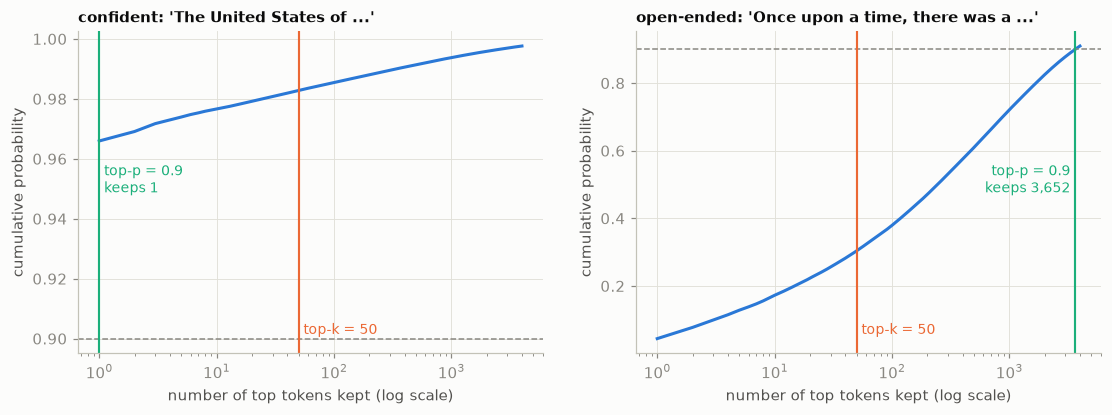

,prompt type,prompt,top token,P(top),mass kept by top-k=50,tokens kept by top-p=0.9,entropy
0,confident,'The United States of',America,0.966,0.983,1,0.37
1,open-ended,"'Once upon a time, there was a'",man,0.044,0.304,3652,7.40


In [13]:
prompts = {
    "confident": "The United States of",
    "open-ended": "Once upon a time, there was a",
}
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
rows = []
for ax, (kind, text) in zip(axes, prompts.items()):
    p = softmax(next_token_logits(text))
    cumulative = np.cumsum(np.sort(p)[::-1])
    k_star = int(np.searchsorted(cumulative, 0.9) + 1)
    shown = 4000
    ax.plot(np.arange(1, shown + 1), cumulative[:shown], color=BLUE)
    ax.axhline(0.9, color=MUTED, ls="--", lw=1)
    ax.axvline(50, color=ORANGE, lw=1.4)
    ax.axvline(k_star, color=AQUA, lw=1.4)
    ax.set_xscale("log")
    ax.text(50 * 1.1, 0.06, "top-k = 50", color=ORANGE, fontsize=9, transform=ax.get_xaxis_transform())
    ax.text(k_star * 1.1 if k_star < 1000 else k_star / 1.1, 0.5, f"top-p = 0.9\nkeeps {k_star:,}", color=AQUA, fontsize=9,
            ha="left" if k_star < 1000 else "right", transform=ax.get_xaxis_transform())
    ax.set_xlabel("number of top tokens kept (log scale)"); ax.set_ylabel("cumulative probability")
    ax.set_title(f"{kind}: '{text} ...'", fontsize=10)
    rows.append((kind, repr(text), tokenizer.decode(int(p.argmax())), round(float(p.max()), 3),
                 round(float(cumulative[49]), 3), k_star, round(entropy(p), 2)))
plt.savefig("assets/6-topk-vs-topp.png")
plt.show()
pd.DataFrame(rows, columns=["prompt type", "prompt", "top token", "P(top)", "mass kept by top-k=50",
                            "tokens kept by top-p=0.9", "entropy"])

**Reading the table.** The two prompts are opposite cases:

- **"The United States of" (confident).** GPT-2 gives " America" 96.6%. There is essentially one right next word.
- **"Once upon a time, there was a" (open-ended).** Man, girl, king, little, dragon... all fit. The top choice, " man", has only 4.4%.

| Column | Confident | Open-ended | What it measures |
|---|---|---|---|
| P(top) | 0.966 | 0.044 | Probability of the single most likely token |
| mass kept by top-k = 50 | 98.3% | **30.4%** | Keep the 50 most likely tokens: how much of the probability do they cover? |
| tokens kept by top-p = 0.9 | **1** | **3,652** | Keep the fewest tokens that add up to 90%: how many is that? |
| entropy (nats) | 0.37 | 7.40 | How spread out the choice is. $e^{H}$ is the "effective number of options": $e^{0.37} \approx 1.4$ against $e^{7.40} \approx 1{,}600$ |

**Top-p adapts to the model's confidence.** On the confident prompt " America" alone already covers $0.966 \ge 0.9$, so top-p keeps one token and sampling is the same as greedy, which is what you want when there is one right answer. On the open prompt it needs 3,652 tokens to reach 90%, so the story can go many ways, which is also what you want.

**Top-k does not adapt, and gets both cases wrong.** It always keeps 50:

- On the confident prompt it keeps " America" plus 49 tokens that share 1.7% of the probability. Over many samples some of those get drawn ("The United States of the...").
- On the open prompt 50 tokens cover only 30% of the probability. The other 70%, thousands of perfectly good words, is thrown away, so samples become blander and more alike.

An analogy: top-k is "always shortlist 50 candidates", whether there is one obvious hire or a thousand good ones. Top-p is "shortlist until you have covered 90% of the likely hires": one when it is obvious, thousands when it is open.

This is the argument for top-p in Holtzman et al. (2020). In practice APIs often set both, for example `top_p = 0.9` with `top_k = 50` as a safety cap on very flat distributions. With $T = 0$ neither matters: greedy decoding takes the top token whatever the filters would keep.

## Repetition, frequency and presence penalties side by side

The two penalty families change logits in different shapes. The multiplicative repetition penalty depends on the sign and size of the logit; the additive ones depend on how many times the token has appeared.

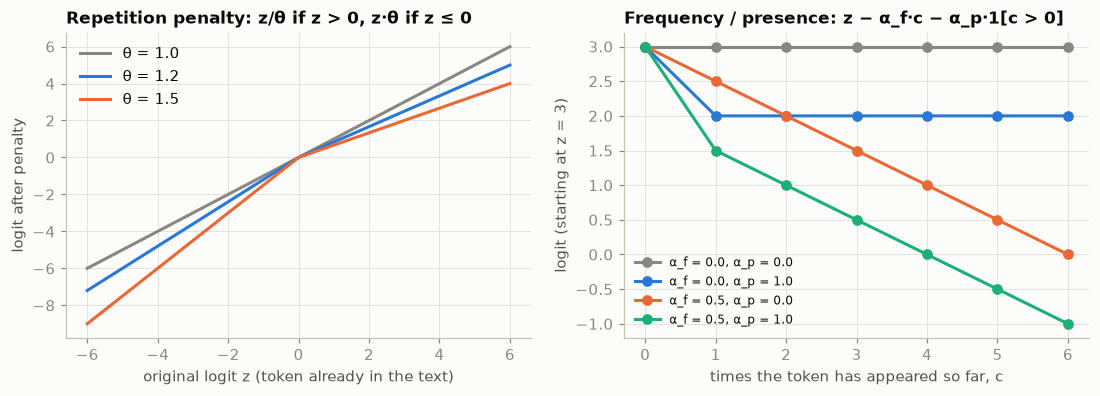

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3.6))
zs = np.linspace(-6, 6, 200)
for theta, color in [(1.0, MUTED), (1.2, BLUE), (1.5, ORANGE)]:
    axes[0].plot(zs, np.where(zs > 0, zs / theta, zs * theta), color=color, label=f"θ = {theta}")
axes[0].set_xlabel("original logit z (token already in the text)"); axes[0].set_ylabel("logit after penalty")
axes[0].set_title("Repetition penalty: z/θ if z > 0, z·θ if z ≤ 0"); axes[0].legend()

counts = np.arange(0, 7)
for (af, ap), color in [((0.0, 0.0), MUTED), ((0.0, 1.0), BLUE), ((0.5, 0.0), ORANGE), ((0.5, 1.0), AQUA)]:
    axes[1].plot(counts, 3.0 - af * counts - ap * (counts > 0), marker="o", color=color, label=f"α_f = {af}, α_p = {ap}")
axes[1].set_xlabel("times the token has appeared so far, c"); axes[1].set_ylabel("logit (starting at z = 3)")
axes[1].set_title("Frequency / presence: z − α_f·c − α_p·1[c > 0]"); axes[1].legend(fontsize=8)
plt.savefig("assets/6-penalties.png")
plt.show()

**Reading the penalty figure.** All three penalties do the same job, making a token that is already in the text less likely to be picked again, by **lowering its logit** before softmax. They differ in how much they lower it.

- **Repetition penalty $\theta$ (left).** Multiplicative, from the CTRL paper (Keskar et al., 2019). A positive logit is divided by $\theta$ and a negative one is multiplied by it, so both move down. $\theta = 1$ is off. The drop is proportional to the size of the logit: with $\theta = 1.3$, $z = 3$ drops by 0.69 but $z = -90$ drops by 27. It ignores how many times the token appeared: once or twenty times gets the same treatment.
- **Frequency penalty $\alpha_f$ (right).** Additive: subtract $\alpha_f$ for **every** earlier occurrence, $z - \alpha_f c$. The more a token has been used, the lower it goes, so it fights loops that grow, and the drop is the same whatever the scale of the logits.
- **Presence penalty $\alpha_p$ (right).** Additive, once: subtract $\alpha_p$ if the token has appeared **at all**. It nudges towards new words and topics, but does not get stronger as a loop continues.

The OpenAI-style APIs expose the two additive ones (`frequency_penalty`, `presence_penalty`, from $-2$ to $2$). Hugging Face and vLLM also expose `repetition_penalty`. Part 4 below shows each of them acting on a real repetition loop.

## Sampling against greedy, on GPT-2

Five continuations of the same prompt under each setting. Greedy gives the same text every time. Sampling at a low temperature stays close to it; sampling at a high temperature with no truncation wanders off; top-p trims the long tail of improbable tokens that causes the wandering.

In [15]:
def generate(prompt, n=5, max_new_tokens=20, **decoding):
    ids = tokenizer(prompt, return_tensors="pt").input_ids
    torch.manual_seed(0)
    out = gpt2.generate(ids, max_new_tokens=max_new_tokens, num_return_sequences=n,
                        pad_token_id=tokenizer.eos_token_id, **decoding)
    return [tokenizer.decode(o[ids.shape[1]:]).replace("\n", " ") for o in out]


prompt = "My favourite thing to do on the weekend is"
settings = {
    "greedy (T = 0)": dict(do_sample=False),
    "T = 0.3": dict(do_sample=True, temperature=0.3, top_k=0, top_p=1.0),
    "T = 1.5, no truncation": dict(do_sample=True, temperature=1.5, top_k=0, top_p=1.0),
    "T = 1.5, top_p = 0.5": dict(do_sample=True, temperature=1.5, top_k=0, top_p=0.5),
    "T = 1.0, repetition_penalty = 1.3": dict(do_sample=True, temperature=1.0, top_k=0, top_p=0.95, repetition_penalty=1.3),
}
samples = {}
for name, decoding in settings.items():
    samples[name] = generate(prompt, n=1 if name.startswith("greedy") else 5, **decoding)
    print(f"--- {name}")
    for s in samples[name]:
        print("   ", repr(s))
print("\ngreedy run twice gives identical text:", samples["greedy (T = 0)"][0] == generate(prompt, n=1, do_sample=False)[0])

--- greedy (T = 0)
    ' to go to the beach and watch the sunset. I love the view of the ocean and the beautiful'
--- T = 0.3
    " to go to the pub and play with your friends. I've been doing this for years and I"
    " to go to a pub and have a pint. It's a great way to get away from the"
    " to go to the beach and watch the sunset. It's a beautiful place to be and I love"
    " to get my hands on a new car and try to get it to the right place. I've"
    ' to take a walk around the park. The park is a bit of a maze and there are a'
--- T = 1.5, no truncation
    ' along Girls Limonite pre IX. Countrymania takes 11 months. Can yes Drive any longer records!'
    ' when your bipartisan commission plans can pass along buttons. Cosponsors: (1) Scott Aschwab'
    " pilot is the Cathin so it optimises triangle being mounted in a lan'latus helicopter If"
    ' play MastgdangPlusBOimation Sanskrit Key Words with upbeat lyrics difficult sometimes Carth%. Includes atomic battery'
    'avetree

**Reading the samples.** Greedy produced the same sentence twice. At $T = 0.3$ the five samples are fluent and close to each other (three start "to go to the"). At $T = 1.5$ with no truncation, every sample turns into nonsense within a few tokens: the flattened distribution gives the 50,000-token tail enough total probability that a junk token is drawn almost every few steps, and each junk token is then part of the input. With `top_p = 0.5` at the same temperature the samples are more grammatical but still drift, because in Hugging Face temperature is applied *before* top-p, so at $T = 1.5$ the top 50% of the probability already contains many tokens. The repetition-penalty run ($T = 1.0$, `top_p` 0.95) is varied and mostly coherent. The seed is the same for every setting, which is why some samples share their first word across settings.

## The comparison matrix

Every parameter, what it acts on, and what moving it in each direction does. The "example" column refers to results in this notebook.

| Parameter | Acts on | Formula | Lower value | Higher value | Example in this notebook | Typical use |
|---|---|---|---|---|---|---|
| `temperature` $T$ | every logit | $p \propto e^{z/T}$ | sharper, more repetitive; $T=0$ is greedy | flatter, more varied, more errors | P(" Paris") vs $T$; entropy curve | 0 for extraction, classification, evaluation; 0.7 to 1.0 for chat and writing |
| `top_k` $K$ | how many tokens survive | keep the $K$ largest | fewer candidates, safer | more candidates; $K = |V|$ is off | top-k=50 keeps 50 tokens whether GPT-2 is sure or not | 40 to 100 as a safety net alongside top-p |
| `top_p` $p$ | how much probability survives | smallest set with mass $\ge p$ | only the head of the distribution | more of the tail; $p=1$ is off | 0.9 keeps a few tokens after "United States of", thousands after "there was a" | 0.9 to 0.95 for sampling; 1.0 with $T=0$ |
| `min_p` | tokens relative to the top one | keep $p_i \ge \text{min\_p} \cdot p_{\max}$ | more of the tail | only tokens close to the top one | 0.05 keeps far fewer than top-p=0.9 on the Eiffel prompt | 0.05 to 0.1, often with higher $T$ |
| `repetition_penalty` $\theta$ | tokens already in the text | $z/\theta$ or $z\theta$ | $\theta=1$ is off | stronger push away from repeats; too high bends grammar | breaks the "binge, binge" loop (Part 4) | 1.0 to 1.2 |
| `frequency_penalty` $\alpha_f$ | repeated tokens, per repeat | $z - \alpha_f c$ | 0 is off; negative encourages repeats | the more often used, the less likely | right panel of the penalty figure | 0 to 0.5 for long text |
| `presence_penalty` $\alpha_p$ | any token seen once | $z - \alpha_p \mathbb{1}[c>0]$ | 0 is off | pushes towards new tokens and topics | right panel of the penalty figure | 0 to 1 for brainstorming, varied synthetic data |
| `max_tokens` | length | stop after $m$ tokens | truncated answers (including cut-off reasoning) | longer, costlier answers | 6.1 reserves 512 tokens for the response | the longest answer you expect, plus margin |
| `stop` | length | stop at a string | | | 6.1 stops at Llama 3's end-of-turn token | end-of-turn tokens, or a delimiter in few-shot prompts |
| `logprobs` | output only | return $\log p$ of chosen tokens | | | Part 3 | debugging, confidence, evaluation |

**Settings by application.** These are common starting points, not rules:

| Application | Suggested settings | Why |
|---|---|---|
| Classification, extraction, grading, LLM-as-judge | $T = 0$ | One answer, reproducible, programmatically checkable |
| Maths and code | $T = 0$ to $0.3$ | One wrong token can break the whole answer |
| Chat assistant | $T = 0.7$, `top_p` = 0.9 | Natural variation without drifting off-topic |
| Brainstorming, fiction | $T = 0.9$ to $1.1$, `top_p` = 0.95, presence penalty 0.5 | Reward novelty |
| Synthetic data at scale (Part 5) | $T = 0.7$ to $1.0$, `top_p` = 0.95 | Diversity across thousands of samples matters more than any single sample |
| Small models that loop | `repetition_penalty` 1.1 to 1.2 | Breaks the feedback loop in Part 4 |

One caution on reproducibility: $T = 0$ requests greedy decoding, but a hosted API can still return slightly different text between calls, because batched floating-point arithmetic on GPUs is not exactly deterministic and two near-tied tokens can swap. Locally, as above, greedy is exactly repeatable.

# Part 3: A basic experimental setup

When trying out a new LLM, or trying to understand one better, three settings make experiments more reproducible and easier to check:

1. **Greedy decoding** ($T = 0$), so the same prompt gives the same answer and differences come from the prompt, not from sampling.
2. **A task with a known answer**, ideally one that can be checked by code.
3. **Token probabilities** (`logprobs`), to see not just *what* the model said but *how sure it was* at each token.

Here is that setup on GPT-2 with a question whose answer is known.

In [16]:
@torch.no_grad()
def greedy_with_probs(prompt, max_new_tokens=12):
    ids = tokenizer(prompt, return_tensors="pt").input_ids
    out = gpt2.generate(ids, max_new_tokens=max_new_tokens, do_sample=False, output_scores=True,
                        return_dict_in_generate=True, pad_token_id=tokenizer.eos_token_id)
    generated = out.sequences[0, ids.shape[1]:]
    rows = []
    for step, (score, tok) in enumerate(zip(out.scores, generated)):
        p = torch.softmax(score[0].double(), dim=-1)
        runner_up = torch.topk(p, 2).indices[1]
        rows.append((step + 1, repr(tokenizer.decode(tok)), round(p[tok].item(), 3), round(np.log(p[tok].item()), 3),
                     repr(tokenizer.decode(runner_up)), round(p[runner_up].item(), 3)))
    return pd.DataFrame(rows, columns=["step", "chosen token", "P", "logprob", "runner-up", "P(runner-up)"])


known_q = "Q: What is the capital of Japan?\nA: The capital of Japan is"
result = greedy_with_probs(known_q, max_new_tokens=6)
answer = tokenizer.decode(gpt2.generate(tokenizer(known_q, return_tensors="pt").input_ids, max_new_tokens=6, do_sample=False,
                                        pad_token_id=tokenizer.eos_token_id)[0])[len(known_q):]
print(f"answer: {answer!r} | correct (contains 'Tokyo'): {'Tokyo' in answer}")
result

answer: ' Tokyo.\nA: The' | correct (contains 'Tokyo'): True


,step,chosen token,P,logprob,runner-up,P(runner-up)
0,1,' Tokyo',0.175,-1.741,' the',0.096
1,2,'.',0.538,-0.620,"','",0.233
2,3,'\n',0.176,-1.737,' It',0.161
3,4,'A',0.068,-2.684,'Q',0.066
4,5,':',0.576,-0.552,'J',0.040
5,6,' The',0.154,-1.868,' It',0.095


GPT-2 answers " Tokyo", but with only 17.5% probability against 9.6% for the runner-up " the": correct, but not confident. Without the probabilities, this answer would look as reliable as "America" after "The United States of" (96.6%).

A task checked by code (here, "does the answer contain Tokyo") means the comparison can be repeated over many prompts without reading every output. Notebook 6.1 applies this setup to a word problem with a numeric answer.


# Part 4: Few-shot prompting and the vicious feedback loop

## Few-shot prompting

Few-shot prompting puts worked examples in the prompt instead of, or as well as, instructions.

- **Pro:** it is sometimes easier to *show* the behaviour you want than to describe it.
- **Con:** the model cannot tell which parts of the examples are meant to generalize. In the course demo, an example with three anagrams of "acres" made the model lean towards producing three anagrams for other words too.

## 4a. The vicious feedback loop, reproduced on GPT-2

The course demo showed the model getting stuck on "being, binge" with rising probabilities. GPT-2 does the same with greedy decoding on a short few-shot anagram prompt. Below, every generated token is shown with the probability the model gave it.

In [17]:
loop_prompt = "Anagrams of 'acres': cares, races, scare.\nAnagrams of 'begin': being, binge"


@torch.no_grad()
def generate_with_probs(prompt, max_new_tokens=60, **decoding):
    ids = tokenizer(prompt, return_tensors="pt").input_ids
    torch.manual_seed(0)
    out = gpt2.generate(ids, max_new_tokens=max_new_tokens, output_scores=True, return_dict_in_generate=True,
                        pad_token_id=tokenizer.eos_token_id, **decoding)
    gen = out.sequences[0, ids.shape[1]:]
    # out.scores are the processed scores (after any penalty), so recompute the model's own probabilities
    full = out.sequences[0].tolist()
    logits = gpt2(torch.tensor([full])).logits[0].double()
    probs = [torch.softmax(logits[ids.shape[1] + t - 1], -1)[tok].item() for t, tok in enumerate(gen.tolist())]
    return tokenizer.decode(gen), np.array(probs), [tokenizer.decode(t) for t in gen]


greedy_text, greedy_p, greedy_tokens = generate_with_probs(loop_prompt, do_sample=False)
penalized_text, penalized_p, penalized_tokens = generate_with_probs(loop_prompt, do_sample=False, repetition_penalty=1.3)
print("greedy                     :", repr(greedy_text[:150]))
print("greedy + repetition_penalty:", repr(penalized_text[:150]))

greedy                     : ', binge, binge, binge, binge, binge, binge, binge, binge, binge, binge, binge, binge, binge, binge, binge, binge, binge, binge, binge, binge, binge, b'
greedy + repetition_penalty: ' drinking and eating out (or at least not in the same way).<|endoftext|>'


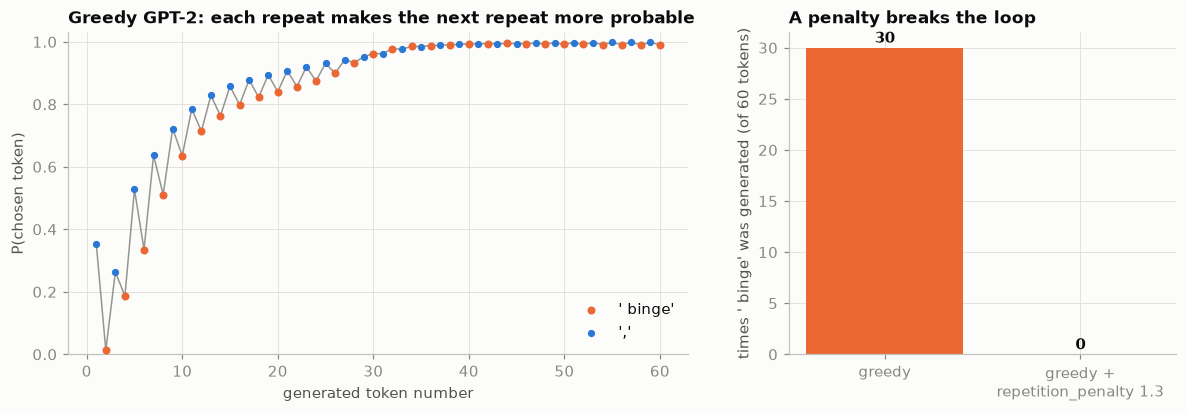

P(' binge') at its 1st, 2nd, 5th, 10th and last repeat: [0.013, 0.186, 0.635, 0.84, 0.991]


In [18]:
binge_steps = [i for i, t in enumerate(greedy_tokens) if t.strip() == "binge"]
fig, axes = plt.subplots(1, 2, figsize=(13, 3.8), gridspec_kw={"width_ratios": [1.6, 1]})
ax = axes[0]
ax.plot(np.arange(1, len(greedy_p) + 1), greedy_p, color=SECONDARY, lw=1, alpha=0.6)
ax.scatter(np.array(binge_steps) + 1, greedy_p[binge_steps], color=ORANGE, s=18, zorder=3, label="' binge'")
others = [i for i in range(len(greedy_p)) if i not in binge_steps]
ax.scatter(np.array(others) + 1, greedy_p[others], color=BLUE, s=14, zorder=3, label="','")
ax.set_ylim(0, 1.03); ax.set_xlabel("generated token number"); ax.set_ylabel("P(chosen token)")
ax.set_title("Greedy GPT-2: each repeat makes the next repeat more probable"); ax.legend(loc="lower right")

ax = axes[1]
counts_binge = [len(binge_steps), sum(t.strip() == "binge" for t in penalized_tokens)]
ax.bar(["greedy", "greedy +\nrepetition_penalty 1.3"], counts_binge, color=[ORANGE, AQUA])
for i, c in enumerate(counts_binge):
    ax.text(i, c + 0.5, str(c), ha="center", fontweight="bold")
ax.set_ylabel("times ' binge' was generated (of 60 tokens)"); ax.set_title("A penalty breaks the loop")
plt.savefig("assets/6-repetition-loop.png")
plt.show()
print("P(' binge') at its 1st, 2nd, 5th, 10th and last repeat:",
      [round(float(greedy_p[binge_steps[i]]), 3) for i in [0, 1, 4, 9, -1]])

This is the loop described in *The Curious Case of Neural Text Degeneration* (Holtzman et al., 2020), the paper that also introduced top-p sampling. Greedy decoding always picks the most probable token. Once " binge" has been repeated a few times, the repeats are part of the input, and the model's estimate that another repeat comes next keeps rising until it is close to 1. Nothing about the anagram task changed; the model is reacting to its own output.

The paper's observation is that the highest-probability text is often *not* human-like text: people rarely repeat themselves like this, so always taking the top token drifts away from natural language. Sampling from a truncated distribution (top-p) and the repetition penalty are two ways around it. With the penalty, each repeat lowers " binge"'s logit instead of being free.

## How each penalty acts on the loop, in numbers

**What the loop is.** Greedy decoding has no memory of "I already said that" beyond the text itself. After the prompt's "being, binge", the most probable next tokens are ", binge" again. Once that is written, the input contains one more "binge", which makes the pattern "binge, binge" look even more established, which raises the probability of the next "binge". Nothing stops it except `max_tokens`. The probabilities above go 0.013, 0.186, 0.635, 0.840, ... 0.991.

**What a penalty does.** Before each step it looks at which tokens are already in the text and lowers their logits, so the model has to pay to repeat. Below, I take the greedy run at the 1st, 2nd, 5th and 10th " binge" and apply each penalty to the model's real logits at that step.

In [19]:
from collections import Counter

ids = tokenizer.encode(loop_prompt)
run = gpt2.generate(torch.tensor([ids]), max_new_tokens=60, do_sample=False, pad_token_id=tokenizer.eos_token_id)[0].tolist()
binge = tokenizer.encode(" binge")[0]
binge_at = [t for t in range(len(ids), len(run)) if run[t] == binge]

rows = []
for k in [0, 1, 4, 9]:
    context = run[:binge_at[k]]                 # everything before this repeat
    z = next_token_logits(context)
    settings = {
        "none": z,
        "repetition 1.3": repetition_penalty(z, context, 1.3),
        "frequency 0.5": frequency_presence_penalty(z, context, 0.5, 0.0),
        "presence 0.5": frequency_presence_penalty(z, context, 0.0, 0.5),
    }
    row = {"repeat": k + 1, "binge seen": Counter(context)[binge], "z(binge)": round(float(z[binge]), 2)}
    for name, zz in settings.items():
        row[f"P, {name}"] = round(float(softmax(zz)[binge]), 4)
    row["top token with repetition 1.3"] = repr(tokenizer.decode([int(np.argmax(settings["repetition 1.3"]))]))
    rows.append(row)
pd.DataFrame(rows)

,repeat,binge seen,z(binge),"P, none","P, repetition 1.3","P, frequency 0.5","P, presence 0.5",top token with repetition 1.3
0,1,1,-74.72,0.0131,0.0000,0.0080,0.0080,' feeling'
1,2,2,-67.48,0.1863,0.0000,0.0783,0.1226,' be'
2,5,5,-25.57,0.6355,0.0008,0.1267,0.5169,' be'
3,10,10,27.26,0.8403,0.0102,0.0350,0.7650,' and'


**Reading the table.**

1. **Without a penalty** " binge" is the top token at every step, and its probability climbs from 0.013 to 0.840 by the tenth repeat. The logit itself climbs from about $-75$ to $+27$: the model becomes sure.
2. **Repetition penalty 1.3** is by far the strongest here, and the reason is the sign of GPT-2's logits. At the first repeat $z = -74.7$ is negative, so it is *multiplied* by 1.3 and falls by 22.4, which is enough to take the probability from 0.013 to essentially 0. The model picks something new (" feeling"), the loop never starts, and the penalized run in the cell above ends in a normal sentence. Because the drop scales with $|z|$, the same $\theta$ is mild on a model whose logits are near 0 and drastic on one whose logits are around $-90$: tune it per model.
3. **Frequency penalty 0.5** grows with the count. With one "binge" in the text it subtracts 0.5; with ten it subtracts 5, and P(" binge") falls from 0.840 to 0.035. It does not prevent the loop from starting, but pushes harder the longer it runs.
4. **Presence penalty 0.5** subtracts 0.5 whatever the count, so by the tenth repeat it barely matters (0.840 to 0.765). It is a nudge towards variety, not a loop breaker.

**The cost.** A penalty cannot tell a bad repeat from a necessary one. In "the patient's patient ID" or in code, where a variable name must be repeated, a strong penalty pushes the model to a synonym or a typo. That is why extraction and code use $T = 0$ with penalties **off**, and penalties are kept for long free text.

## Who decides when to be greedy?

**Not the model.** The model only produces logits. Temperature, top-k, top-p and the penalties are applied by the code around it, the `generate` loop or the API server, with values fixed by **whoever sends the request**. The model never sees them and cannot change them, and an API applies the same values to every token of the response.

So "go greedy" is a decision made in advance, per task:

| Task | Who sets it | What they set | Why |
|---|---|---|---|
| Extraction, classification, maths, code, evaluation | the application developer | $T = 0$ (greedy) | one right answer, reproducible |
| Chat | the application developer | $T \approx 0.7$, `top_p` 0.9 | natural variety without drifting |
| Creative writing, brainstorming | the application developer, sometimes the end user | $T \approx 1$, `top_p` 0.95, presence penalty | reward novelty |

**Within one response, top-p and min-p already adapt per token.** Neither looks at the entropy directly, but both behave as if they did. On a confident step (low entropy) they keep one or a few tokens, which is effectively greedy; on an open step (high entropy) they keep many. The table above showed it: top-p keeps 1 token after "The United States of" and 3,652 after "there was a". Setting `top_p` is how you get "greedy when sure, varied when not" without choosing per token.

**Methods that use the entropy explicitly** exist, but are not standard API parameters:

- *Mirostat* (Basu et al., 2021) adjusts truncation at every step to keep the surprise of the text near a target.
- *Locally typical sampling* (Meister et al., 2023) keeps tokens whose surprise is close to the entropy of the current step.
- *Entropy-based dynamic temperature* (Zhang et al., 2024) lowers the temperature when the entropy is low and raises it when it is high.

Note the direction: these methods are designed to make **open** steps (high entropy) *more* varied, not greedy. For a task with one right answer, a high-entropy step means the model is **unsure**, as with " Tokyo" at 17.5% in Part 3. Forcing it to be greedy there does not make the answer more correct. It only hides the uncertainty. The useful response is to measure it, with `logprobs` or the entropy of the step, and treat a low-confidence answer differently, for example by asking for a check or abstaining.

## 4b. Few-shot anagrams on gpt-oss-120b

The second effect from the course demo: does a one-example prompt showing **three** anagrams push the model towards three anagrams for every word? I ask for all anagrams of eight words, once zero-shot and once with the "acres" example, at $T = 0$. Every returned word is checked against the macOS word list (`/usr/share/dict/words`): it must use exactly the same letters and be in the list.

gpt-oss-120b is a reasoning model: before the visible answer it writes hidden reasoning, which the API does not return but does count towards `max_tokens`. `together_chat` therefore adds a separate budget for it and asks for `reasoning_effort = "low"`, so that `max_tokens` keeps its meaning of "how long the answer may be". The hidden reasoning also means the model can think about the anagrams before it commits to a list, which a 2023-era model answering directly could not.

In [20]:
REASONING_BUDGET = 1024   # tokens for gpt-oss's hidden reasoning, on top of the answer's max_tokens


def together_chat(messages, max_tokens=256, temperature=0.0, top_p=1.0, reasoning_effort="low", **extra):
    """One call to Together AI's OpenAI-compatible chat completions endpoint."""
    response = requests.post(
        "https://api.together.xyz/v1/chat/completions",
        headers={"Authorization": f"Bearer {TOGETHER_API_KEY}", "Content-Type": "application/json"},
        json={"model": TOGETHER_MODEL, "messages": messages, "max_tokens": max_tokens + REASONING_BUDGET,
              "reasoning_effort": reasoning_effort, "temperature": temperature, "top_p": top_p, **extra},
        timeout=120,
    )
    response.raise_for_status()
    return response.json()


DICTIONARY = {w.strip().lower() for w in open("/usr/share/dict/words")} if os.path.exists("/usr/share/dict/words") else set()
WORDS = ["listen", "night", "earth", "stone", "angel", "dusty", "below", "lemon"]
FEW_SHOT = "Q: List all anagrams of 'acres'.\nA: cares, races, scare\n\n"


def anagram_prompt(word, few_shot):
    return (FEW_SHOT if few_shot else "") + f"Q: List all anagrams of '{word}'. Answer with a comma-separated list only.\nA:"


def parse_and_check(word, text):
    candidates = [w.strip(" .'\"").lower() for w in text.strip().split("\n")[0].split(",") if w.strip(" .'\"")]
    valid = [w for w in candidates if sorted(w) == sorted(word) and w != word and w in DICTIONARY]
    return candidates, valid


if not TOGETHER_AVAILABLE:
    print("Skipped: set TOGETHER_API_KEY to run this cell.")
else:
    rows = []
    for word in WORDS:
        for few_shot in [False, True]:
            reply = together_chat([{"role": "user", "content": anagram_prompt(word, few_shot)}], max_tokens=60)
            text = reply["choices"][0]["message"]["content"]
            candidates, valid = parse_and_check(word, text)
            rows.append((word, "few-shot" if few_shot else "zero-shot", text.strip().split("\n")[0][:60],
                         len(candidates), len(valid)))
    anagrams = pd.DataFrame(rows, columns=["word", "prompt", "reply", "words returned", "valid anagrams"])
    display(anagrams)
    summary = anagrams.groupby("prompt").agg(
        mean_returned=("words returned", "mean"),
        replies_with_exactly_3=("words returned", lambda s: int((s == 3).sum())),
        valid_share=("valid anagrams", "sum"),
    )
    summary["valid_share"] = summary["valid_share"] / anagrams.groupby("prompt")["words returned"].sum()
    display(summary.round(2))

,word,prompt,reply,words returned,valid anagrams
0,listen,zero-shot,"enlist, silent, tinsel, inlets, listen",5,3
1,listen,few-shot,"enlist, silent, tinsel, inlets, elints, listen",6,3
2,night,zero-shot,"night, thing",2,1
3,night,few-shot,"night, thing",2,1
4,earth,zero-shot,"earth, hater, heart, rathe",4,3
5,earth,few-shot,"earth, hater, heart, rathe",4,3
6,stone,zero-shot,"stone, seton, tones, onset, steno, notes",6,3
7,stone,few-shot,"stone, tones, seton, onset, notes, steno",6,3
8,angel,zero-shot,"angel, angle, glean",3,2
9,angel,few-shot,"angel, glean, angle",3,2


,mean_returned,replies_with_exactly_3,valid_share
prompt,,,
few-shot,3.38,2,0.59
zero-shot,3.50,3,0.61


**Result.** gpt-oss-120b did **not** copy the example's count. For 6 of the 8 words the zero-shot and few-shot replies contain the same words, sometimes in a different order. Both prompts average 3.4 words per reply, and exactly three words came back twice zero-shot and once few-shot. The three-anagram pull from the course demo does not appear. A plausible reason is the hidden reasoning: the model works through the letters before it commits to a list, rather than continuing the example's pattern token by token, which is what produced the effect in older models.

The example did change something, and it was its **format** rather than its count. In 15 of the 16 replies the model lists the word itself among its anagrams ("listen" in the anagrams of "listen"), which the check rejects. The one reply that leaves it out is the few-shot reply for "lemon" (just "melon"), matching the example, where "acres" is not in its own list.

Two caveats on the "valid share" column (59% zero-shot, 63% few-shot). Apart from the word itself, the only rejected words are "inlets", "tones" and "notes": real words, but plurals, which the macOS word list does not contain. So apart from repeating the input word, the model returned no wrong anagrams. And eight words are far too few to measure a bias reliably (see the limitations at the end).

# Part 5: LLMs as generators of training data

The fine-tuning in notebooks 4 to 5 needed labelled examples. LLMs can produce such data along three dimensions. In each case the table shows what exists already, what the LLM writes, and what the data trains.

| Method | Already have | LLM generates | Record | Trains |
|---|---|---|---|---|
| A. Responses for existing queries | instructions $x$ | responses $\hat y$ | `{"prompt": x, "completion": ŷ}` | instruction fine-tuning (SFT) |
| B. Instructions for existing documents (back-translation) | documents $y$ | instructions $\hat x$ | `{"prompt": x̂, "completion": y}` | instruction fine-tuning (SFT) |
| C. Preferences for existing responses | prompt $x$ with two completions $y_a, y_b$ | a preference | `{"prompt": x, "completion": y_a, "pref": +1}` vs `{..., "completion": y_b, "pref": -1}` | reward model / RLHF, or DPO |

## The math behind each

**A and B: supervised fine-tuning.** Both produce (prompt, completion) pairs. A student model with weights $\phi$ is trained to maximize the probability of the completion given the prompt, which, by the chain rule from Part 1, is a sum over completion tokens:

$$\mathcal{L}_{\text{SFT}}(\phi) = -\sum_{(x, y)} \sum_{t=1}^{|y|} \log P_\phi\big(y_t \mid x, y_{<t}\big).$$

The prompt tokens are input only; the loss is computed on the completion.

The difference is **which side the LLM wrote**. In A the completion is model-written, so the student learns to imitate the teacher's answers. In B the completion is an existing human-written document, and only the instruction is model-written. *Self-Alignment with Instruction Backtranslation* (Li et al., 2023) trains a backward model $P(x \mid y)$ on a small seed set, uses it to write an instruction $\hat x$ for each unlabelled web document $y$, then has the model rate each $(\hat x, y)$ pair and keeps only the highest-rated pairs. The name comes from machine translation for low-resource languages, where monolingual text in the target language is translated *back* into the source language to create training pairs.

**C: preferences.** A judge (a person in RLHF, an LLM here) says which of two completions is better. The standard model of such comparisons is Bradley-Terry: each completion has a latent quality, or reward, $r(x, y)$, and

$$P(y_a \succ y_b \mid x) = \sigma\big(r(x, y_a) - r(x, y_b)\big), \qquad \sigma(u) = \frac{1}{1+e^{-u}}.$$

A reward model $r_\psi$ is fitted to judged pairs (winner $y_w$, loser $y_l$) by minimizing $-\log \sigma\big(r_\psi(x, y_w) - r_\psi(x, y_l)\big)$, and the LLM is then optimized against it with reinforcement learning. Direct Preference Optimization (Rafailov et al., 2023) skips the separate reward model and trains the policy $\pi_\theta$ directly, relative to a frozen reference $\pi_{\text{ref}}$:

$$\mathcal{L}_{\text{DPO}} = -\log \sigma\Big(\beta \log \frac{\pi_\theta(y_w \mid x)}{\pi_{\text{ref}}(y_w \mid x)} - \beta \log \frac{\pi_\theta(y_l \mid x)}{\pi_{\text{ref}}(y_l \mid x)}\Big).$$

When the judge is an LLM following a written set of principles, as in *Constitutional AI: Harmlessness from AI Feedback* (Bai et al., 2022), this is RL from AI feedback: the method is the same, but the feedback is not human.

**Licences.** Before training on a model's outputs, check that its licence allows it. For example, the Llama 3.x community licences permit using outputs to improve another model, with conditions (such as including "Llama" at the start of that model's name if it is distributed). gpt-oss, used below, is released under Apache 2.0, which places no such condition on its outputs; the API provider's terms of service apply on top of either licence.

## A small live run

One call per method, at $T = 0$ so the outputs are reproducible enough to read. At scale, method A would use a higher temperature (see the settings table in Part 2) to get varied responses. For method C, I ask the judge twice with the two completions in **swapped order**: an LLM judge can prefer whichever answer it sees first (position bias), and a preference only counts if it survives the swap.

In [21]:
SYNTHETIC_PATH = "data/6-synthetic-examples.jsonl"

instruction = "Explain in two sentences what the temperature parameter does when sampling from an LLM."
document_chunk = ("Nucleus sampling truncates the next-token distribution to the smallest set of tokens whose "
                  "cumulative probability exceeds a threshold p, renormalizes, and samples from that set. Because "
                  "the set grows when the model is uncertain and shrinks when it is confident, it avoids both the "
                  "repetitive output of greedy decoding and the incoherent tail of pure sampling.")
completion_a = "Temperature divides the logits before the softmax. Lower values make the most likely tokens even more likely; higher values flatten the distribution and give more varied, less predictable text."
completion_b = "Temperature controls how hot the GPU runs while generating text. Higher temperature means faster but less accurate answers."


def ask(prompt_text, system=None, max_tokens=200):
    messages = ([{"role": "system", "content": system}] if system else []) + [{"role": "user", "content": prompt_text}]
    return together_chat(messages, max_tokens=max_tokens)["choices"][0]["message"]["content"].strip()


def judge(prompt_text, first, second):
    verdict = ask(
        f"Question:\n{prompt_text}\n\nResponse 1:\n{first}\n\nResponse 2:\n{second}\n\n"
        "Which response is more accurate and helpful? Reply with exactly '1' or '2'.",
        system="You are a careful evaluator.", max_tokens=3)
    return verdict.strip()[:1]


if not TOGETHER_AVAILABLE:
    print("Skipped: set TOGETHER_API_KEY to run this cell.")
else:
    records = []
    # A. response for an existing instruction
    response_a = ask(instruction)
    records.append({"method": "A", "prompt": instruction, "completion": response_a})
    # B. instruction for an existing document (back-translation)
    generated_instruction = ask(
        "Write the single user instruction or question to which the following text would be an ideal answer. "
        f"Reply with the instruction only.\n\nText:\n{document_chunk}", max_tokens=60)
    records.append({"method": "B", "prompt": generated_instruction, "completion": document_chunk})
    # C. preference between two existing completions, checked with the order swapped
    v_ab, v_ba = judge(instruction, completion_a, completion_b), judge(instruction, completion_b, completion_a)
    consistent = (v_ab == "1" and v_ba == "2") or (v_ab == "2" and v_ba == "1")
    pref_a = 1 if (v_ab == "1" and consistent) else -1 if consistent else 0
    records.append({"method": "C", "prompt": instruction, "completion": completion_a, "pref": pref_a})
    records.append({"method": "C", "prompt": instruction, "completion": completion_b, "pref": -pref_a})

    with open(SYNTHETIC_PATH, "w") as f:
        for r in records:
            f.write(json.dumps(r) + "\n")

    print("A. completion written for the existing instruction:\n  ", response_a, "\n")
    print("B. instruction back-translated from the existing document:\n  ", generated_instruction, "\n")
    print(f"C. judge verdicts: order (a, b) -> '{v_ab}', order (b, a) -> '{v_ba}', consistent after swap: {consistent}")
    print(f"\n{len(records)} records written to {SYNTHETIC_PATH}")
    display(pd.DataFrame(records).assign(completion=lambda d: d.completion.str[:70] + "..."))

A. completion written for the existing instruction:
   The temperature parameter controls how “random” or “deterministic” the model’s token sampling is: a low temperature (e.g., 0.1–0.5) makes the softmax distribution sharper, causing the model to pick higher‑probability tokens more often and produce more predictable, focused output; a high temperature (e.g., 1.0–2.0) flattens the distribution, increasing the chance of lower‑probability tokens and yielding more diverse, creative, but potentially less coherent results. 

B. instruction back-translated from the existing document:
   Explain how nucleus (top‑p) sampling works and why it tends to produce better text than greedy decoding or pure random sampling. 

C. judge verdicts: order (a, b) -> '1', order (b, a) -> '2', consistent after swap: True

4 records written to data/6-synthetic-examples.jsonl


,method,prompt,completion,pref
0,A,Explain in two sentences what the temperature ...,The temperature parameter controls how “random...,NaN
1,B,Explain how nucleus (top‑p) sampling works and...,Nucleus sampling truncates the next-token dist...,NaN
2,C,Explain in two sentences what the temperature ...,Temperature divides the logits before the soft...,1.0
3,C,Explain in two sentences what the temperature ...,Temperature controls how hot the GPU runs whil...,-1.0


**Reading the live run.**

- **A (response for an existing instruction).** The answer is correct, but it is one long sentence, not the two that were asked for. A generator does not reliably follow format and length instructions, so a synthetic-data pipeline needs a filter step (length, format, a quality judge) before anything is trained on.
- **B (back-translation).** The generated instruction, *"Explain how nucleus (top-p) sampling works and why it helps avoid the repetitive output of greedy decoding and the incoherent tail of pure random sampling"*, is a question the document fully answers, and it reuses the document's own phrases. That makes the pair consistent, and it is also a known weakness of back-translation: generated instructions tend to paraphrase the answer, so they are easier and more uniform than real user questions.
- **C (preference).** The judge picked the correct completion (temperature divides the logits) over the wrong one (GPU heat) in both orders, so the preference survives the swap and is recorded as $+1$ for completion a and $-1$ for b. With two completions this different, any capable judge should agree. Position bias shows up on close pairs, which is where the swap check earns its cost.

# Part 6: API playgrounds

Playgrounds (the [OpenAI Playground](https://platform.openai.com/playground), the [Together AI Playground](https://api.together.ai/playground), which serves open-weight models) are a quick way to iterate on a prompt before writing code. Every slider in a playground is one field of the request body used in this notebook and in 6.1:

| Playground control | Request field |
|---|---|
| System message | `messages[0]` with `"role": "system"` |
| Temperature, Top P, Top K | `temperature`, `top_p`, `top_k` |
| Repetition / frequency / presence penalty | `repetition_penalty`, `frequency_penalty`, `presence_penalty` |
| Maximum length | `max_tokens` |
| Stop sequences | `stop` |
| Show probabilities | `logprobs` |

A prompt worked out in a playground carries over to code unchanged if those fields are copied too. A prompt tested at $T = 0.7$ and then run at $T = 0$, or the other way round, is a different experiment.

# Summary

| Part | Finding |
|---|---|
| 1 | A prompt is the $X$ in $P(Y \mid X, \theta)$. The chain-rule factorization of $\log P(Y \mid X)$ into per-token terms was checked on GPT-2 and is exact. |
| 2 | Temperature rescales logit gaps without reordering tokens; entropy can only rise with $T$ ($dH/dT = \operatorname{Var}(z)/T^3$, checked numerically). Top-p adapts the number of candidates to the model's confidence, unlike top-k. My NumPy implementation of every step matches Hugging Face's. |
| 3 | Greedy decoding, a known answer and token probabilities make experiments repeatable and checkable. |
| 4 | Greedy GPT-2 reproduces the "being, binge" loop, with the repeat's probability rising towards 1; a repetition penalty of 1.3 removes it, a frequency penalty weakens it as it grows, a presence penalty barely touches it. On gpt-oss-120b, a one-example prompt did not change how many anagrams came back, only whether the input word was listed. |
| 5 | The three synthetic-data formats differ in which side of the pair the LLM writes; A and B train with the SFT loss, C with a Bradley-Terry reward model or DPO. |

**Limitations.**

- GPT-2 small is a 2019 model with 124M parameters. Decoding parameters act on its distribution exactly as on a modern model's, but a modern instruction-tuned model is far more confident and far less prone to loops, so the size of each effect is larger here.
- Hosted APIs may apply the decoding steps in a different order, or implement a parameter slightly differently, from Hugging Face. The formulas here describe the common definitions.
- The few-shot and synthetic-data runs are a handful of calls each. They show the mechanics, not reliable rates.

**References.**

- Holtzman et al. (2020). *The Curious Case of Neural Text Degeneration.* ICLR. [arXiv:1904.09751](https://arxiv.org/abs/1904.09751)
- Keskar et al. (2019). *CTRL: A Conditional Transformer Language Model for Controllable Generation.* [arXiv:1909.05858](https://arxiv.org/abs/1909.05858) (repetition penalty)
- Nguyen et al. (2024). *Turning Up the Heat: Min-p Sampling for Creative and Coherent LLM Outputs.* [arXiv:2407.01082](https://arxiv.org/abs/2407.01082)
- Li et al. (2023). *Self-Alignment with Instruction Backtranslation.* [arXiv:2308.06259](https://arxiv.org/abs/2308.06259)
- Bai et al. (2022). *Constitutional AI: Harmlessness from AI Feedback.* [arXiv:2212.08073](https://arxiv.org/abs/2212.08073)
- Rafailov et al. (2023). *Direct Preference Optimization.* [arXiv:2305.18290](https://arxiv.org/abs/2305.18290)
- Hugging Face blog, *How to generate text.* [huggingface.co/blog/how-to-generate](https://huggingface.co/blog/how-to-generate)
- API references: [OpenAI](https://platform.openai.com/docs/api-reference/chat/create), [Together AI](https://docs.together.ai/reference/chat-completions-1)